# Classification Lab (Logistic Regression and k Nearest Neighbors)

In [25]:
import pandas as pd

from sklearn import neighbors

# Load Titanic data set

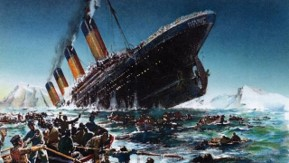

In [26]:
#load the titanic dataset into a data frame
df = pd.read_csv('titanic.csv')

In [27]:
#Show data frame content and check the shape of your dataframe (number of rows and columns)
#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Notice that "Survived" is the classification label of the data set

# Explore data set

Show descriptive statistics of your data frame

In [28]:
#Show some info about the data frame (columns, missing values, data types)
#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [29]:
#Show descriptive statistics of your data frame
#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Data Preparation

In [30]:
#shuffle data frame using the "sample" method
df=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

In [31]:
#Remove Name, Ticket and Cabin from dataset - you can use the drop method
df=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>
df

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
865,866,1,2,female,42.0,0,0,13.0000,S
799,800,0,3,female,30.0,1,1,24.1500,S
712,713,1,1,male,48.0,1,0,52.0000,S
420,421,0,3,male,NaN,0,0,7.8958,C
660,661,1,1,male,50.0,2,0,133.6500,S
...,...,...,...,...,...,...,...,...,...
820,821,1,1,female,52.0,1,1,93.5000,S
798,799,0,3,male,30.0,0,0,7.2292,C
332,333,0,1,male,38.0,0,1,153.4625,S
313,314,0,3,male,28.0,0,0,7.8958,S


In [32]:
#Apply one hot encoding to "Sex" and "Embarked" and show results
sex_oh_encoded = pd.get_dummies(df['Sex'], prefix='Sex')
#sex_oh_encoded

embarked_oh_encoded = #<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>
embarked_oh_encoded

,Embarked_C,Embarked_Q,Embarked_S
865,0,0,1
799,0,0,1
712,0,0,1
420,1,0,0
660,0,0,1
...,...,...,...
820,0,0,1
798,1,0,0
332,0,0,1
313,0,0,1


In [33]:
#Join one hot encoded features "Sex" and "Embarked" to data frame and show result
df=df.join#<<<<<<<<<<<<<<<<<<<<<<< insert code here >>>>>>>>>>>>>>>>>>>>>>>>>>
df=df.join(embarked_oh_encoded, lsuffix='_df', rsuffix='_embarked_oh_encoded')
df

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
865,866,1,2,female,42.0,0,0,13.0000,S,1,0,0,0,1
799,800,0,3,female,30.0,1,1,24.1500,S,1,0,0,0,1
712,713,1,1,male,48.0,1,0,52.0000,S,0,1,0,0,1
420,421,0,3,male,NaN,0,0,7.8958,C,0,1,1,0,0
660,661,1,1,male,50.0,2,0,133.6500,S,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
820,821,1,1,female,52.0,1,1,93.5000,S,1,0,0,0,1
798,799,0,3,male,30.0,0,0,7.2292,C,0,1,1,0,0
332,333,0,1,male,38.0,0,1,153.4625,S,0,1,0,0,1
313,314,0,3,male,28.0,0,0,7.8958,S,0,1,0,0,1


What is the problem with the result of this join?

Right, the features "Sex" and "Embarked" are now redundantly stored in the data set (nominal and one hot encoding)

In [34]:
#remove the original (nominal-encoded) features
df=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>
df

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
865,866,1,2,42.0,0,0,13.0000,1,0,0,0,1
799,800,0,3,30.0,1,1,24.1500,1,0,0,0,1
712,713,1,1,48.0,1,0,52.0000,0,1,0,0,1
420,421,0,3,NaN,0,0,7.8958,0,1,1,0,0
660,661,1,1,50.0,2,0,133.6500,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
820,821,1,1,52.0,1,1,93.5000,1,0,0,0,1
798,799,0,3,30.0,0,0,7.2292,0,1,1,0,0
332,333,0,1,38.0,0,1,153.4625,0,1,0,0,1
313,314,0,3,28.0,0,0,7.8958,0,1,0,0,1


In [35]:
#Replace missing values for Age with mean value - you can use the methods "fillna" and "mean"
df['Age'] = #<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,0.352413,0.647587,0.188552,0.086420,0.722783
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429,0.477990,0.477990,0.391372,0.281141,0.447876
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,0.000000,0.000000
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200,0.000000,1.000000,0.000000,0.000000,1.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,0.000000,0.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,1.000000,1.000000,1.000000,1.000000


Create (pandas) histograms for all (numeric) features execpt "PassengerID" using the dataframe method "hist"

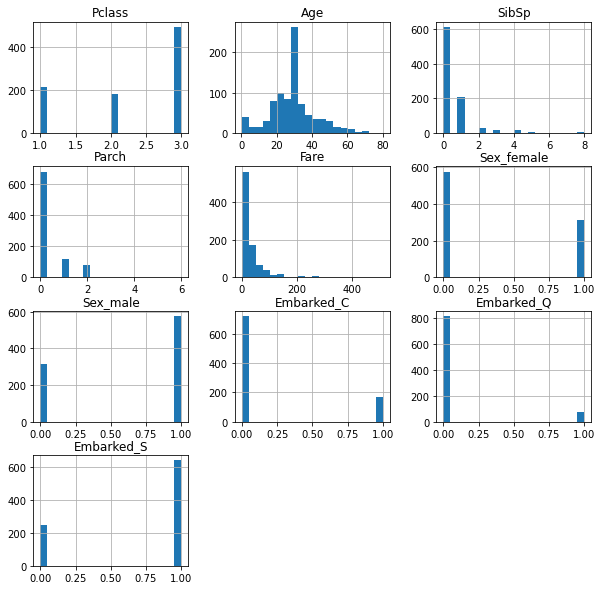

In [36]:
hist = #<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

# Model Building

Split data into training and test data (500 training examples) and features vs. label

In [37]:
num_training_examples=500

#Split data to training and test test
df_train=df.iloc[:num_training_examples,:]
df_test=df.iloc[num_training_examples:,:]

#Split training data to features and label ('Survived')
train_features=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>
train_label=df_train['Survived']

#Split test data to features and label ('Survived')
test_features=df_test.drop('Survived',axis=1)
test_label=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

#check the results
#test_features

Initialize and fit a logistics regression model, using the training data

In [38]:
from sklearn.linear_model import LogisticRegression

lr = #<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

In [39]:
#evaluate model with test data
lr.score(test_features,test_label)

0.7953964194373402

Initialize and fit a kNN model, using the training data

In [40]:
from sklearn import neighbors

#initialize the model
knn = neighbors.KNeighborsClassifier(n_neighbors=10)
#fit the model
#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

KNeighborsClassifier(n_neighbors=10)

In [41]:
#evaluate model with test data
#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

0.670076726342711

# Results visualization

In [42]:
#Predict each test label using your logistic regression and knn model
lr_prediction=lr.predict(test_features)
knn_prediction=#<<<<<<<<<<<<<<<<<<<<<<< insert line of code here >>>>>>>>>>>>>>>>>>>>>>>>>>

In [43]:
#Reconstruct test data in a data frame
df_test=pd.DataFrame(test_features)

#add actual label to data frame
df_test['actual_label']=test_label

#add predicted labels to data frame
df_test['lr_prediction']=lr_prediction
df_test['knn_prediction']=knn_prediction

df_test

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,actual_label,lr_prediction,knn_prediction
541,542,3,9.000000,4,2,31.2750,1,0,0,0,1,0,0,0
669,670,1,29.699118,1,0,52.0000,1,0,0,0,1,1,1,0
80,81,3,22.000000,0,0,9.0000,0,1,0,0,1,0,0,0
583,584,1,36.000000,0,0,40.1250,0,1,1,0,0,0,1,1
557,558,1,29.699118,0,0,227.5250,0,1,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
820,821,1,52.000000,1,1,93.5000,1,0,0,0,1,1,1,1
798,799,3,30.000000,0,0,7.2292,0,1,1,0,0,0,0,0
332,333,1,38.000000,0,1,153.4625,0,1,0,0,1,0,0,1
313,314,3,28.000000,0,0,7.8958,0,1,0,0,1,0,0,0


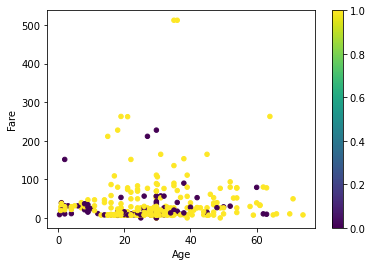

In [49]:
#plot actual label vs. lr-predicted lab for test data in scatter plot using Age and Fare on x/y axis
# Scatter Plot
scatter = df_test.plot.scatter(x='Age', y='Fare', 
                           c=#<<<<<<<<<<<<< add code here >>>>>>>>>>>>>>>>>,
                               colormap='viridis',sharex=False)

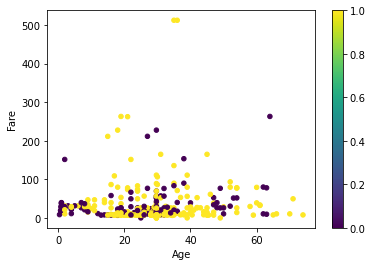

In [50]:
#plot actual label vs. knn-predicted lab for test data in scatter plot using Age and Fare on x/y axis
# Scatter Plot
scatter = df_test.plot.scatter(x='Age', y='Fare', 
                           c=df_test['actual_label'] == df_test['knn_prediction'].astype(int),colormap='viridis',sharex=False)